In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

pd.options.display.float_format = "{:,.1f}".format

model = joblib.load("../models/model_xgb.joblib")
X_test = pd.read_csv("../data/processed/X_test.csv")
y_test_log = pd.read_csv("../data/processed/y_test_log.csv").squeeze("columns")

ev = pd.DataFrame({
    "asli_juta":    np.expm1(y_test_log) / 1e6,
    "tebakan_juta": np.expm1(model.predict(X_test)) / 1e6,
})
ev["meleset_pct"] = (ev["tebakan_juta"] - ev["asli_juta"]).abs() / ev["asli_juta"] * 100
ev["arah"] = np.where(ev["tebakan_juta"] > ev["asli_juta"], "kemahalan", "kemurahan")

kolom_kota = [c for c in X_test.columns if c.startswith("city_")]
ev["kota"] = X_test[kolom_kota].idxmax(axis=1).str.replace("city_", "")
ev["luas_bangunan"] = X_test["building_size_m2"]

print("MAPE:", round(ev["meleset_pct"].mean(), 1), "| median:", round(ev["meleset_pct"].median(), 1))
ev.head()

MAPE: 20.3 | median: 13.3


,asli_juta,tebakan_juta,meleset_pct,arah,kota,luas_bangunan
0,"2,700.0","3,186.3",18.0,kemahalan,Bekasi,136.0
1,"5,360.0","3,913.2",27.0,kemurahan,Bekasi,370.0
2,"1,980.0","2,204.4",11.3,kemahalan,Bekasi,98.0
3,"2,000.0","1,804.5",9.8,kemurahan,Bekasi,155.0
4,"1,900.0","1,490.0",21.6,kemurahan,Bekasi,120.0


In [2]:
ev["kelas_harga"] = pd.qcut(ev["asli_juta"], 4, labels=["murah", "sedang", "mahal", "sangat mahal"])

ev.groupby("kelas_harga", observed=True).agg(
    jumlah=("asli_juta", "size"),
    harga_maks_juta=("asli_juta", "max"),
    mape=("meleset_pct", "mean"),
    median_meleset=("meleset_pct", "median"),
)

,jumlah,harga_maks_juta,mape,median_meleset
kelas_harga,,,,
murah,160,875.0,21.3,12.9
sedang,160,"1,580.0",17.4,14.7
mahal,161,"4,200.0",19.0,12.8
sangat mahal,158,"110,000.0",23.5,13.5


,jumlah,mape,median_meleset
kota,,,
Depok,82,14.1,11.6
Jakarta_Barat,40,14.9,11.4
Tangerang,164,19.0,12.8
Jakarta_Timur,9,20.6,18.8
Jakarta_Utara,23,20.7,16.4
Bogor,162,21.3,10.9
Bekasi,117,23.7,18.0
Jakarta_Selatan,34,28.1,23.2
Jakarta_Pusat,8,33.8,27.3


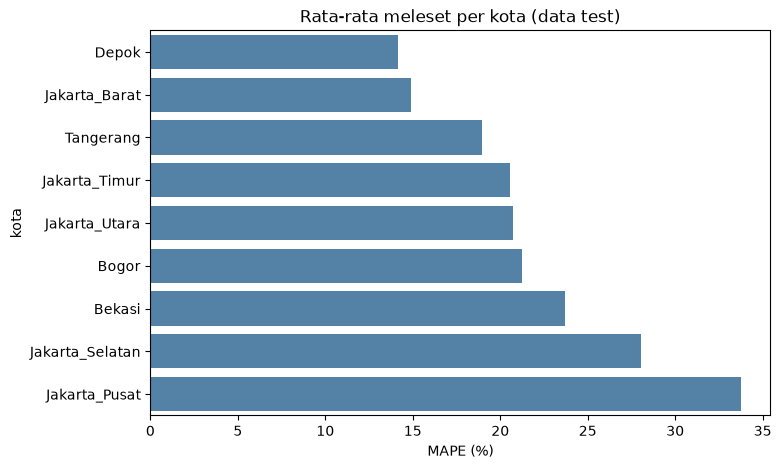

In [3]:
per_kota = (ev.groupby("kota")
              .agg(jumlah=("asli_juta", "size"),
                   mape=("meleset_pct", "mean"),
                   median_meleset=("meleset_pct", "median"))
              .sort_values("mape"))
display(per_kota)

plt.figure(figsize=(8, 5))
sns.barplot(x=per_kota["mape"], y=per_kota.index, color="steelblue")
plt.xlabel("MAPE (%)")
plt.title("Rata-rata meleset per kota (data test)")
plt.show()

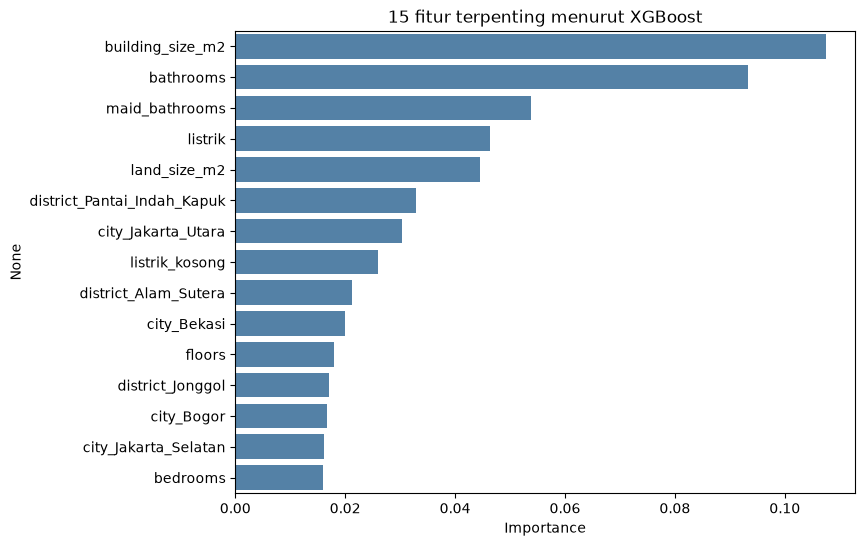

In [4]:
importance = (pd.Series(model.feature_importances_, index=X_test.columns)
                .sort_values(ascending=False)
                .head(15))

plt.figure(figsize=(8, 6))
sns.barplot(x=importance.values, y=importance.index, color="steelblue")
plt.xlabel("Importance")
plt.title("15 fitur terpenting menurut XGBoost")
plt.show()

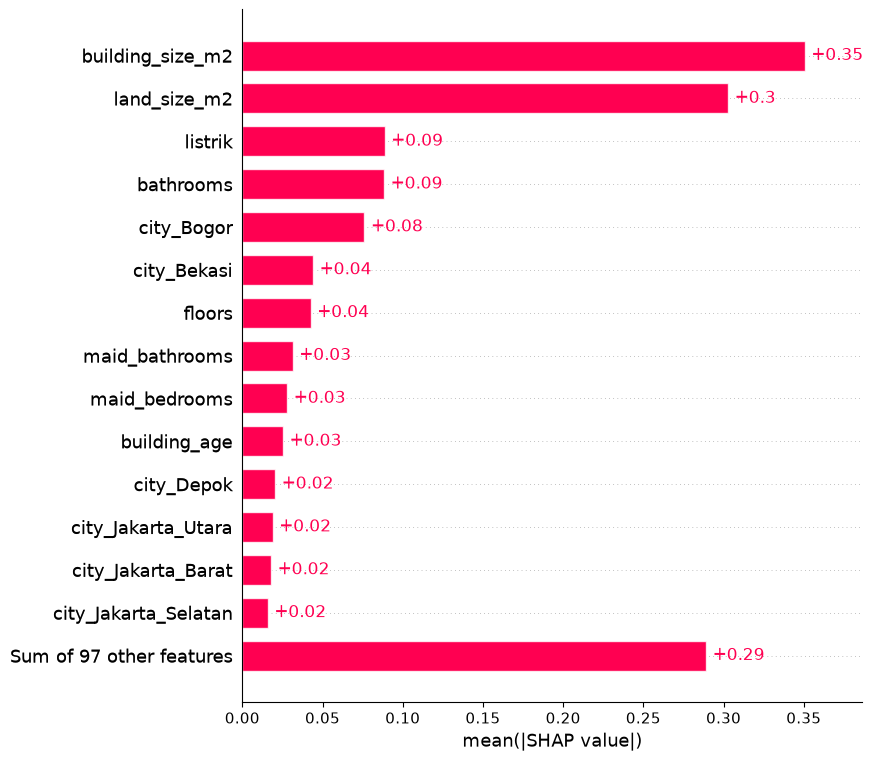

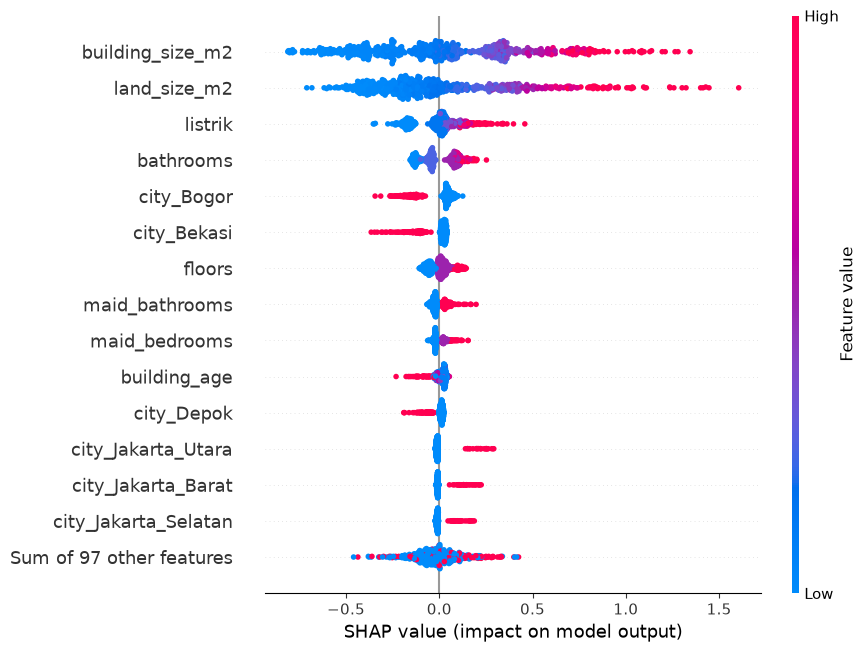

In [5]:
import shap

explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)

shap.plots.bar(shap_values, max_display=15)
shap.plots.beeswarm(shap_values, max_display=15)

Harga asli : 2700.0 juta
Tebakan    : 3186.3 juta


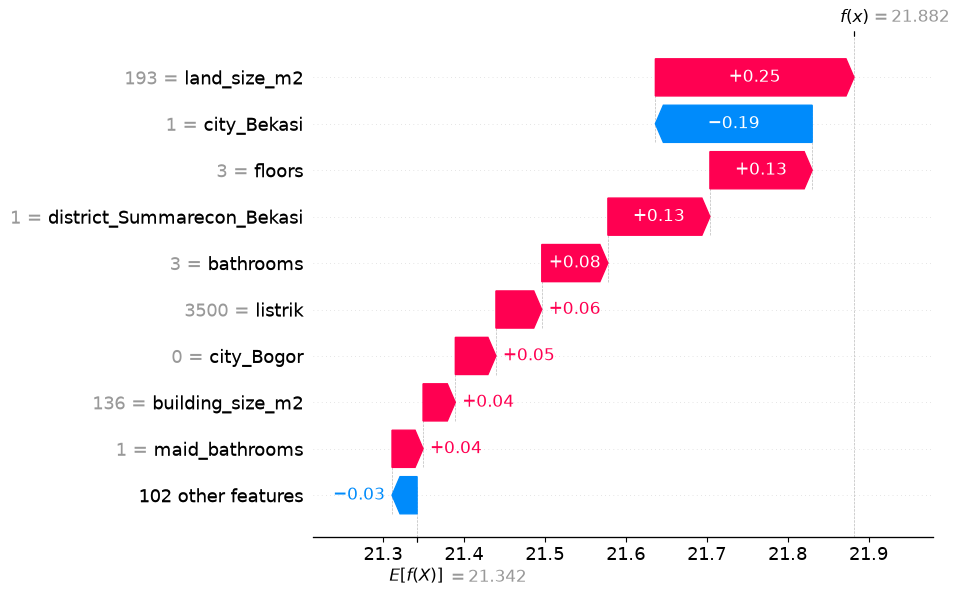

In [6]:
i = 0
print("Harga asli :", round(ev.loc[i, "asli_juta"], 1), "juta")
print("Tebakan    :", round(ev.loc[i, "tebakan_juta"], 1), "juta")

shap.plots.waterfall(shap_values[i], max_display=10)